# SANPO-Synthetic: exploration (chest + head, official train split)

Explores the data made by `prepare_sanpo_synthetic_modal.py` on the Modal Volume, **before** the validation split and training.

**Where things run:** this notebook runs on this PC. The heavy work (reading 91k masks) runs on Modal, next to the data,
through Modal functions defined in this notebook (Modal's official notebook pattern: `app.run()`,
https://modal.com/docs/guide/jupyter-notebooks). Only small results come back. They are cached in `results/`, so
running the notebook again is instant.

**Questions it answers:**
1. How many walks and frames per camera, and how long are the walks?
2. Which frame rate was each walk rendered at (5, 14.28 or 33.33 FPS)? SANPO does not store it; the distance the camera
   moves between frames reveals it.
3. Which classes appear, how often, and how does that compare with the real chest data?
4. What do the frames and masks look like?

SANPO: https://google-research-datasets.github.io/sanpo_dataset/ | paper https://arxiv.org/abs/2309.12172

## 1. Settings

In [30]:
from pathlib import Path

SESSION = "session3"                   # Modal session (workspace) that holds the synthetic data
VOLUME_NAME = "sanpo"                  # Modal Volume
DATASET = "sanpo_synthetic"            # folder made by prepare_sanpo_synthetic_modal.py
REAL_HEAD_DATASET = "sanpo_real_head"  # folder made by ../head/prepare_sanpo_real_head_modal.py (same session)
REAL_CLASS_PIXELS = Path("../../../data/sanpo/sanpo_real_chest/views/class_pixels_v1/class_pixels_per_frame.csv").resolve()
REAL_VALIDATION_WALKS = Path("../chest/validation_split/results/validation_walks.txt").resolve()
RESULTS_DIR = Path("results").resolve()  # cached results of the Modal work (delete a file to recompute it)
PARALLEL_WALKS = 20                    # Modal containers reading masks at the same time (read only: no commit limit)
SAMPLE_IMAGES = 6                      # frames shown in section 7 (random, fixed seed)
SEED = 42
# expected frame rates (SANPO WACV 2025 supplement: 60% of walks at 5 FPS, 20% at 14.28, 20% at 33.33)
FRAME_RATES = [5.0, 14.28, 33.33]
# Frame rate per walk: SANPO's description.json (fps) for every walk. Batch_3 is labeled 20 FPS but its camera moves
# 0.50 m per frame (10 m/s at 20 FPS, i.e. not walking; 2.5 m/s at 5 FPS) and the SANPO paper lists only 5, 14.28 and
# 33.33 FPS: we treat it as 5 FPS (section 5 shows the numbers). Thinning keeps every round(fps / TARGET_FPS)-th frame.
WALK_METADATA_FILE = RESULTS_DIR / "walk_metadata.csv"   # cached per-walk metadata from the public bucket (section 5)
EFFECTIVE_FPS = {"Batch_3_5_18_2023": 5.0}            # render batch -> frame rate we use instead of its label
TARGET_FPS = 5.0
SANPO_SYNTHETIC_URL = "https://storage.googleapis.com/gresearch/sanpo_dataset/v0/sanpo-synthetic/"

## 2. Imports and Modal setup

In [31]:
import io
import json
import os
import sys

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# choose the Modal session BEFORE importing modal (it reads the config file at import)
os.environ["MODAL_CONFIG_PATH"] = str(Path.home() / f".modal_{SESSION}.toml")
import modal

pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 220)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
LOCAL_PYTHON = f"{sys.version_info.major}.{sys.version_info.minor}"   # Modal needs the same Python version remotely
print("Python", LOCAL_PYTHON, "| modal", modal.__version__, "| session", SESSION)

app = modal.App("blind-guide-explore-synthetic")
volume = modal.Volume.from_name(VOLUME_NAME)
image = modal.Image.debian_slim(python_version=LOCAL_PYTHON).apt_install("libgl1", "libglib2.0-0").pip_install(
    "numpy", "opencv-python-headless")

Python 3.12 | modal 1.4.2 | session session3


## 3. Modal functions (run next to the data)

They return only plain Python values (lists, dicts, bytes), so no library version has to match between Modal and this PC.

In [32]:
@app.function(image=image, volumes={"/data": volume}, timeout=1800)
def read_indexes(dataset: str = DATASET) -> list:
    """Every index CSV of a dataset folder (one row per frame). Returns a list of row dicts."""
    import csv
    rows = []
    for path in sorted(Path(f"/data/{dataset}/index").glob("*.csv")):
        with open(path, newline="") as handle:
            rows += list(csv.DictReader(handle))
    return rows


@app.function(image=image, volumes={"/data": volume}, timeout=3600, cpu=1, max_containers=PARALLEL_WALKS)
def class_pixels_of_walk(mask_paths: list, dataset: str = DATASET) -> list:
    """Pixels per raw SANPO class id (0..30) for each mask of one walk of a dataset folder.
    Returns [[mask path, [31 counts + count of ids above 30]], ...]."""
    import cv2
    import numpy as np
    result = []
    for path in mask_paths:
        mask = cv2.imread(f"/data/{dataset}/{path}", cv2.IMREAD_COLOR)       # BGR: red (class id) = index 2
        counts = np.bincount(mask[:, :, 2].ravel(), minlength=256)
        result.append([path, counts[:31].tolist() + [int(counts[31:].sum())]])   # last value: ids above 30 (must be 0)
    return result


@app.function(image=image, volumes={"/data": volume}, timeout=600)
def sample_images(pairs: list, width: int = 640, dataset: str = DATASET) -> list:
    """[(frame path, mask path)] of a dataset folder -> [(frame JPG bytes, mask red channel PNG bytes)], resized to
    `width` pixels."""
    import cv2
    out = []
    for frame_path, mask_path in pairs:
        frame = cv2.imread(f"/data/{dataset}/{frame_path}")
        mask = cv2.imread(f"/data/{dataset}/{mask_path}", cv2.IMREAD_COLOR)[:, :, 2]
        height = round(frame.shape[0] * width / frame.shape[1])
        frame = cv2.resize(frame, (width, height), interpolation=cv2.INTER_AREA)
        mask = cv2.resize(mask, (width, height), interpolation=cv2.INTER_NEAREST)
        out.append((cv2.imencode(".jpg", frame)[1].tobytes(), cv2.imencode(".png", mask)[1].tobytes()))
    return out

## 4. Frames and walks per camera

In [33]:
index_cache = RESULTS_DIR / "index_all.csv"
if index_cache.exists():
    frames = pd.read_csv(index_cache, dtype={"frame_id": str})
else:
    with modal.enable_output(), app.run():
        # read_indexes takes: nothing; returns: one dict per frame from every index CSV
        frames = pd.DataFrame(read_indexes.remote())
    frames.to_csv(index_cache, index=False)
frames["step_m"] = pd.to_numeric(frames["step_m"], errors="coerce")
walks = frames.groupby("session").agg(camera=("camera", "first"), frames=("frame_id", "size"),
                                      median_step_m=("step_m", "median"), width=("width", "first"),
                                      height=("height", "first"))
print(f"{len(frames):,} frames in {len(walks):,} walks")
display(walks.groupby("camera").agg(walks=("frames", "size"), frames=("frames", "sum"),
                                     median_frames_per_walk=("frames", "median"), min_frames=("frames", "min"),
                                     max_frames=("frames", "max")))
print("frame sizes:", frames.groupby(["width", "height"]).size().to_dict())
print("camera tracking states:", frames["tracking_state"].value_counts().to_dict())

90,945 frames in 1,560 walks


,walks,frames,median_frames_per_walk,min_frames,max_frames
camera,,,,,
chest,773,46390,50.0,50,167
head,787,44555,50.0,50,167


frame sizes: {(2208, 1242): 90945}
camera tracking states: {'TrackingState.READY': 90945}


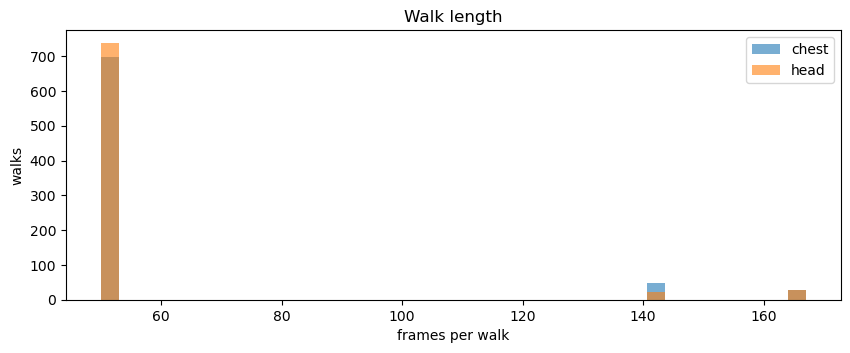

In [34]:
figure, axis = plt.subplots(figsize=(10, 3.5))
for camera, part in walks.groupby("camera"):
    axis.hist(part["frames"], bins=40, alpha=0.6, label=camera)
axis.set_xlabel("frames per walk"); axis.set_ylabel("walks"); axis.legend(); axis.set_title("Walk length")
plt.show()

## 5. Frame rate, clip length and render batch of each walk

SANPO-Synthetic stores per walk: **`description.json`** with the frame rate (`fps`) and the camera intrinsics, and,
in `left/temp/histogram-*.json`, the **original Parallel Domain file path**, which names the **render batch** (a
delivery of rendered walks, with its date) and the scene, e.g. `.../pd/Batch_3_5_18_2023/batch_3_chest/scene_000892/`.
Both are fetched once from the public bucket (small files, about 2 minutes) and cached in `results/walk_metadata.csv`.

**Cross-check:** the camera moves at walking speed, so the distance per frame (`step_m`, from `camera_poses.csv`)
times the frame rate should be a walking speed (about 1 to 2.5 m/s). **Batch_3** (labeled 20 FPS) gives 10 m/s at
20 FPS but 2.5 m/s at 5 FPS, and the SANPO paper lists only 5, 14.28 and 33.33 FPS: it is treated as 5 FPS
(`EFFECTIVE_FPS` in the settings).

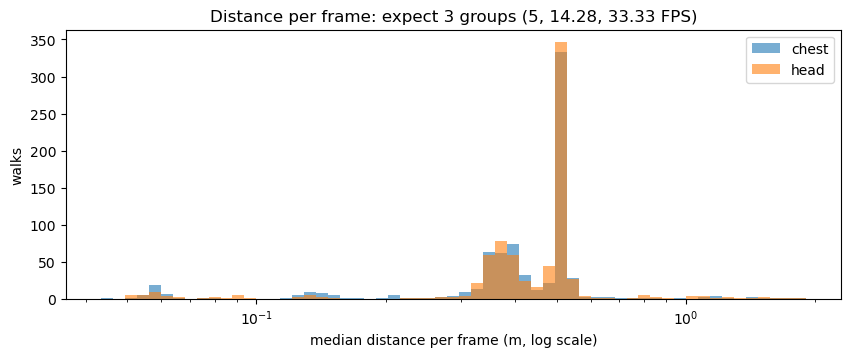

count    1560.0000
mean        0.4524
std         0.1995
min         0.0435
25%         0.3734
50%         0.4967
75%         0.5073
max         1.9012


In [35]:
figure, axis = plt.subplots(figsize=(10, 3.5))
bins = np.logspace(np.log10(max(walks["median_step_m"].min(), 1e-3)), np.log10(walks["median_step_m"].max()), 60)
for camera, part in walks.groupby("camera"):
    axis.hist(part["median_step_m"], bins=bins, alpha=0.6, label=camera)
axis.set_xscale("log"); axis.set_xlabel("median distance per frame (m, log scale)"); axis.set_ylabel("walks")
axis.legend(); axis.set_title("Distance per frame: expect 3 groups (5, 14.28, 33.33 FPS)")
plt.show()
print(walks["median_step_m"].describe().round(4).to_string())

In [36]:
import re
import urllib.parse
import urllib.request
from concurrent.futures import ThreadPoolExecutor


def fetch(path: str) -> bytes:
    """A file of the public SANPO-Synthetic bucket (path relative to sanpo-synthetic/), with retries."""
    for attempt in range(5):
        try:
            with urllib.request.urlopen(SANPO_SYNTHETIC_URL + urllib.parse.quote(path), timeout=60) as response:
                return response.read()
        except Exception:
            if attempt == 4:
                raise


def walk_metadata(session_and_camera):
    """description.json (fps, intrinsics) + the Parallel Domain source path of one walk. Returns a dict."""
    session, camera = session_and_camera
    details = (json.loads(fetch(f"{session}/description.json")).get("session_camera_details") or [{}])[0]
    camera_parameters = details.get("left_camera_params", {})
    source = json.loads(fetch(f"{session}/camera_{camera}/left/temp/histogram-000000.json")).get("filename", "")
    match = re.search(r"/pd/([^/]+)/(.*?)/?(scene_\d+)/semantic_segmentation_2d/", source)
    return {"session": session, "labeled_fps": details.get("fps"), "fx": camera_parameters.get("fx"),
            "batch": match.group(1) if match else "", "batch_folder": match.group(2) if match else "",
            "scene": match.group(3) if match else "", "source": source}


if WALK_METADATA_FILE.exists():
    metadata = pd.read_csv(WALK_METADATA_FILE, keep_default_na=False)
else:
    with ThreadPoolExecutor(32) as pool:
        # walk_metadata takes: (walk id, camera); returns: its fps, focal length, batch, scene and source path
        metadata = pd.DataFrame(list(pool.map(walk_metadata, list(zip(walks.index, walks["camera"])))))
    metadata.to_csv(WALK_METADATA_FILE, index=False)
for column in ("labeled_fps", "fx", "batch", "batch_folder", "scene"):
    walks[column] = walks.index.map(metadata.set_index("session")[column])
walks["labeled_fps"] = walks["labeled_fps"].astype(float)
walks["fps"] = [EFFECTIVE_FPS.get(batch, fps) for batch, fps in zip(walks["batch"], walks["labeled_fps"])]
walks["seconds"] = walks["frames"] / walks["fps"]
print(f"walks without a parsed batch: {(walks['batch'] == '').sum()} | walks per scene id: "
      f"{walks.groupby(['batch', 'batch_folder', 'scene']).size().max()} at most")
batches = walks.groupby(["batch", "batch_folder", "camera"]).agg(
    walks=("frames", "size"), frames_per_walk=("frames", "median"), labeled_fps=("labeled_fps", "first"),
    fps_used=("fps", "first"), seconds=("seconds", "median"), median_step_m=("median_step_m", "median"),
    focal_length_px=("fx", "median"))
batches["speed_at_labeled_fps_m_s"] = (batches["median_step_m"] * batches["labeled_fps"]).round(2)
batches["speed_at_fps_used_m_s"] = (batches["median_step_m"] * batches["fps_used"]).round(2)
display(batches.round(3))

walks without a parsed batch: 0 | walks per scene id: 1 at most


walks  frames_per_walk  labeled_fps  fps_used  seconds  median_step_m  focal_length_px  speed_at_labeled_fps_m_s  speed_at_fps_used_m_s
batch                                     batch_folder        camera                                                                                                                                         
Batch_2pt0_04_06_2023                     Chest               chest     143             50.0          5.0       5.0   10.000          0.368         1914.203                      1.84                   1.84
                                          Head                head      145             50.0          5.0       5.0   10.000          0.362         1376.470                      1.81                   1.81
Batch_2pt1_04_06_2023                     Chest               chest      44             50.0          5.0       5.0   10.000          0.768         1914.203                      3.84                   3.84
                                          Head                head       51             50.0          5.0       5.0   10.000          0.871         1376.470                      4.36                   4.36
Batch_3_5_18_2023                         batch_3_chest       chest     408             50.0         20.0       5.0   10.000          0.504         1914.203                     10.09                   2.52
                                          batch_3_head        head      436             50.0         20.0       5.0   10.000          0.501         1376.470                     10.01                   2.50
PD_Goku_Batch_1_Hue_Transformed_1_23_2023 High_FPS_Chest      chest      16            167.0         33.0      33.0    5.061          0.057         1914.203                      1.89                   1.89
                                          High_FPS_Head       head       14            167.0         33.0      33.0    5.061          0.057         1376.470                      1.87                   1.87
                                          Low_FPS_Chest       chest      53             50.0          5.0       5.0   10.000          0.386         1914.203                      1.93                   1.93
                                          Low_FPS_Head        head       55             50.0          5.0       5.0   10.000          0.382         1376.470                      1.91                   1.91
                                          Med_FPS_Chest       chest      13            143.0         14.0      14.0   10.214          0.133         1914.203                      1.86                   1.86
                                          Med_FPS_Head        head       12            143.0         14.0      14.0   10.214          0.133         1376.470                      1.86                   1.86
PD_Goku_Batch_1pt1_2_2_2023               High_FPS/Zed_2      chest      12            167.0         33.0      33.0    5.061          0.059         1914.203                      1.94                   1.94
                                          High_FPS/Zed_Mini   head       13            167.0         33.0      33.0    5.061          0.059         1376.470                      1.95                   1.95
                                          Low_FPS/Zed_2       chest      49             50.0          5.0       5.0   10.000          0.390         1914.203                      1.95                   1.95
                                          Low_FPS/Zed_Mini    head       51             50.0          5.0       5.0   10.000          0.387         1376.470                      1.94                   1.94
                                          Medium_FPS/Zed_2    chest      14            143.0         14.0      14.0   10.214          0.137         1914.203                      1.91                   1.91
                                          Medium_FPS/Zed_Mini head       10            143.0         14.0      14.0   10.214          0.086         1376.470

In [37]:
# Thinning every walk to about TARGET_FPS: keep every round(fps / TARGET_FPS)-th frame (5 FPS: all, 14: every 3rd = 4.67
# FPS, 33: every 7th = 4.71 FPS; Batch_3 counts as 5 FPS, see above). Per camera and frame rate: frames, KEPT, REMOVED.
walks["stride"] = [max(1, round(fps / TARGET_FPS)) for fps in walks["fps"]]
walks["kept"] = [int(np.ceil(n / stride)) for n, stride in zip(walks["frames"], walks["stride"])]
walks["removed"] = walks["frames"] - walks["kept"]
walks["group"] = [f"{fps:g} FPS" + (" (Batch_3, labeled 20)" if batch in EFFECTIVE_FPS else "")
                  for fps, batch in zip(walks["fps"], walks["batch"])]
rows = []
for camera in ("chest", "head"):
    for group in sorted(walks["group"].unique(), key=lambda g: (float(g.split()[0]), g)):
        part = walks[(walks["camera"] == camera) & (walks["group"] == group)]
        if len(part):
            rows.append({"camera": camera, "frame rate": group, "walks": len(part),
                         "keep every": int(part["stride"].iloc[0]), "frames": int(part["frames"].sum()),
                         "kept": int(part["kept"].sum()), "removed": int(part["removed"].sum())})
    part = walks[walks["camera"] == camera]
    rows.append({"camera": camera, "frame rate": "all", "walks": len(part), "keep every": "",
                 "frames": int(part["frames"].sum()), "kept": int(part["kept"].sum()), "removed": int(part["removed"].sum())})
rows.append({"camera": "both", "frame rate": "all", "walks": len(walks), "keep every": "", "frames": int(walks["frames"].sum()),
             "kept": int(walks["kept"].sum()), "removed": int(walks["removed"].sum())})
thinning = pd.DataFrame(rows).set_index(["camera", "frame rate"])
thinning["kept %"] = (100 * thinning["kept"] / thinning["frames"]).round(1)
display(thinning)
batch_3 = walks["batch"].isin(list(EFFECTIVE_FPS))
if_20 = int(walks.loc[batch_3, "frames"].apply(lambda n: int(np.ceil(n / 4))).sum())
print(f"Kept: {walks['kept'].sum():,} of {walks['frames'].sum():,} frames ({100 * walks['kept'].sum() / walks['frames'].sum():.1f}%). "
      f"If Batch_3 were really 20 FPS (every 4th frame): {walks['kept'].sum() - walks.loc[batch_3, 'kept'].sum() + if_20:,}.")

walks keep every  frames   kept  removed  kept %
camera frame rate                                                                   
chest  5 FPS                          289          1   14450  14450        0   100.0
       5 FPS (Batch_3, labeled 20)    408          1   20400  20400        0   100.0
       14 FPS                          48          3    6864   2304     4560    33.6
       33 FPS                          28          7    4676    672     4004    14.4
       all                            773              46390  37826     8564    81.5
head   5 FPS                          302          1   15100  15100        0   100.0
       5 FPS (Batch_3, labeled 20)    436          1   21800  21800        0   100.0
       14 FPS                          22          3    3146   1056     2090    33.6
       33 FPS                          27          7    4509    648     3861    14.4
       all                            787              44555  38604     5951    86.6
both   all                           1560              90945  76430    14515    84.0

Kept: 76,430 of 90,945 frames (84.0%). If Batch_3 were really 20 FPS (every 4th frame): 45,202.


## 6. Classes: synthetic vs real chest

In [38]:
pixels_cache = RESULTS_DIR / "class_pixels_per_frame.csv"
labelmap = None
if pixels_cache.exists():
    pixels = pd.read_csv(pixels_cache)
else:
    masks_per_walk = [list(part["mask"]) for _, part in frames.groupby("session")]
    rows, number = [], 0
    # Jupyter runs its own event loop, so Modal's map must be iterated with "async for" over .map.aio()
    # (Modal's message: "You can't iter(Function.map()) from an async function"); Jupyter allows await in a cell
    with modal.enable_output():
        async with app.run.aio():
            # class_pixels_of_walk takes: one walk's mask paths; returns: [mask path, 31 class pixel counts + out-of-range]
            async for result in class_pixels_of_walk.map.aio(masks_per_walk, order_outputs=False):
                rows += result
                number += 1
                if number % 100 == 0 or number == len(masks_per_walk):
                    print(f"  {number}/{len(masks_per_walk)} walks", flush=True)
    real_header = pd.read_csv(REAL_CLASS_PIXELS, nrows=0).columns[1:].tolist()   # the 31 class names, in id order
    pixels = pd.DataFrame([[path] + counts for path, counts in rows], columns=["mask"] + real_header + ["ids_above_30"])
    pixels.to_csv(pixels_cache, index=False)
class_names = [c for c in pixels.columns if c not in ("mask", "ids_above_30")]
print(f"{len(pixels):,} masks | pixels with ids above 30 (must be 0): {int(pixels['ids_above_30'].sum())}")

90,945 masks | pixels with ids above 30 (must be 0): 0


In [39]:
# Real head: the 5 fps frames of the official train walks (the head training walks + its 7 validation walks), the same
# frames as the real chest numbers above (5 fps, official train). Class pixels counted on Modal, cached like the others.
real_head_cache = RESULTS_DIR / "real_head_class_pixels_per_frame.csv"
if real_head_cache.exists():
    real_head = pd.read_csv(real_head_cache)
else:
    with modal.enable_output():
        async with app.run.aio():
            # read_indexes takes: a dataset folder; returns: one dict per frame from its index CSVs
            head_index = pd.DataFrame(await read_indexes.remote.aio(REAL_HEAD_DATASET))
            head_index = head_index[(head_index["split"] == "train") & (head_index["in_5fps"] == "True")]
            masks_per_walk = [list(part["mask"]) for _, part in head_index.groupby("session")]
            rows, number = [], 0
            # class_pixels_of_walk takes: one walk's mask paths, the dataset folder; returns: [mask path, counts]
            async for result in class_pixels_of_walk.map.aio(masks_per_walk, kwargs={"dataset": REAL_HEAD_DATASET},
                                                             order_outputs=False):
                rows += result
                number += 1
                if number % 20 == 0 or number == len(masks_per_walk):
                    print(f"  {number}/{len(masks_per_walk)} real head walks", flush=True)
    real_head = pd.DataFrame([[path] + counts for path, counts in rows], columns=["mask"] + class_names + ["ids_above_30"])
    real_head.to_csv(real_head_cache, index=False)
print(f"real head: {len(real_head):,} frames (5 fps, official train walks) | ids above 30: {int(real_head['ids_above_30'].sum())}")

real head: 11,218 frames (5 fps, official train walks) | ids above 30: 0


In [40]:
# Real chest: official train walks only (our training walks + the 12 validation walks), from the real class-pixel file
real = pd.read_csv(REAL_CLASS_PIXELS)
real = real[real["mask"].str.contains("/train/|/val/")]
camera_of_mask = frames.set_index("mask")["camera"]
pixels["camera"] = pixels["mask"].map(camera_of_mask)


def shares(table):
    """pixel share % and frame share % per class (frame share = frames that contain the class)."""
    values = table[class_names]
    return pd.DataFrame({"pixel %": 100 * values.sum() / values.values.sum(), "frames %": 100 * (values > 0).mean()})


comparison = pd.concat({"real chest": shares(real), "real head": shares(real_head),
                        "synthetic chest": shares(pixels[pixels["camera"] == "chest"]),
                        "synthetic head": shares(pixels[pixels["camera"] == "head"])}, axis=1).round(3)
display(comparison.sort_values(("real chest", "pixel %"), ascending=False))

real chest          real head          synthetic chest          synthetic head         
                           pixel % frames %   pixel % frames %         pixel % frames %        pixel % frames %
sidewalk                    18.386   59.911     4.822   36.424          17.671   99.545         18.721   99.794
paved trail                 16.903   50.539     9.066   55.839           0.000    0.000          0.000    0.000
building                    13.200   82.940    12.153   63.737          37.222   99.996         39.155   99.991
wall/fence                   8.080   74.016     8.005   70.423           0.225   36.814          0.211   45.427
vegetation                   6.888   77.120    20.368   90.489           1.021   26.439          1.161   31.117
road                         6.320   60.381     2.427   41.638          10.520   97.644         11.685   98.651
obstacle                     5.599   84.903     1.923   64.307           1.539   94.454          1.415   96.894
terrain                      3.832   41.913     6.617   64.709           2.475   86.396          2.989   93.603
vehicle                      3.725   64.664     3.121   47.620           2.458   84.850          2.116   88.248
tree                         2.911   62.445     7.716   62.355           5.310   90.573          5.113   97.190
crosswalk                    2.696   19.337     1.214   12.935           0.468   64.400          0.453   69.231
pedestrian                   2.567   62.376     2.264   61.009           7.067   83.059          2.690   85.907
other walkable surface       2.532   30.305     0.362   16.634           0.000    0.000          0.000    0.000
unlabeled                    1.273   90.755     1.484   82.564           0.098   16.678          0.098   19.782
sky                          1.198   46.068    15.619   83.830          11.530   94.094         12.121   95.733
pole                         0.868   72.650     0.768   67.935           1.145   95.249          0.864   96.427
curb                         0.697   55.164     0.468   53.833           0.853   97.269          0.858   98.793
stairs                       0.694    8.765     0.279    6.169           0.000    0.000          0.000    0.000
hand rail                    0.564    8.546     0.066    5.669           0.000    0.000          0.000    0.000
opening-door                 0.315   11.864     0.528   12.239           0.000    0.000          0.000    0.000
guard rail/road barrier      0.191    5.110     0.271   10.635           0.000    0.000          0.000    0.000
opening-gate                 0.141    5.468     0.092    4.279           0.000    0.000          0.000    0.000
bike rack                    0.135   14.857     0.099    4.208           0.049   48.765          0.057   64.828
water body                   0.105    5.180     0.081    7.158           0.000    0.000          0.000    0.000
inaccessible surface         0.056    2.070     0.027    5.126           0.000    0.000          0.000    0.000
traffic sign                 0.041   16.948     0.019    8.058           0.107   81.714          0.106   84.754
animal                       0.040    6.999     0.033   12.730           0.000    0.009          0.000    0.000
traffic light                0.024   13.374     0.038   12.025           0.227   61.852          0.176   61.234
rider                        0.016    2.662     0.062    6.837           0.013   26.141          0.012   31.956
railway track                0.003    0.155     0.000    0.000           0.000    0.000          0.000    0.000
bus stop                     0.000    0.000     0.010    1.150           0.000    0.000          0.000    0.000

classes absent from ALL synthetic frames: ['guard rail/road barrier', 'paved trail', 'hand rail', 'opening-door', 'opening-gate', 'stairs', 'water body', 'other walkable surface', 'inaccessible surface', 'railway track', 'bus stop']
bus stop pixels in synthetic: 0 (ignored in training, like the real data)

classes in fewer than 1% of the frames of one camera:


real chest          real head          synthetic chest          synthetic head         
                           pixel % frames %   pixel % frames %         pixel % frames %        pixel % frames %
guard rail/road barrier      0.191    5.110     0.271   10.635             0.0    0.000            0.0      0.0
paved trail                 16.903   50.539     9.066   55.839             0.0    0.000            0.0      0.0
hand rail                    0.564    8.546     0.066    5.669             0.0    0.000            0.0      0.0
opening-door                 0.315   11.864     0.528   12.239             0.0    0.000            0.0      0.0
opening-gate                 0.141    5.468     0.092    4.279             0.0    0.000            0.0      0.0
animal                       0.040    6.999     0.033   12.730             0.0    0.009            0.0      0.0
stairs                       0.694    8.765     0.279    6.169             0.0    0.000            0.0      0.0
water body                   0.105    5.180     0.081    7.158             0.0    0.000            0.0      0.0
other walkable surface       2.532   30.305     0.362   16.634             0.0    0.000            0.0      0.0
inaccessible surface         0.056    2.070     0.027    5.126             0.0    0.000            0.0      0.0
railway track                0.003    0.155     0.000    0.000             0.0    0.000            0.0      0.0
bus stop                     0.000    0.000     0.010    1.150             0.0    0.000            0.0      0.0

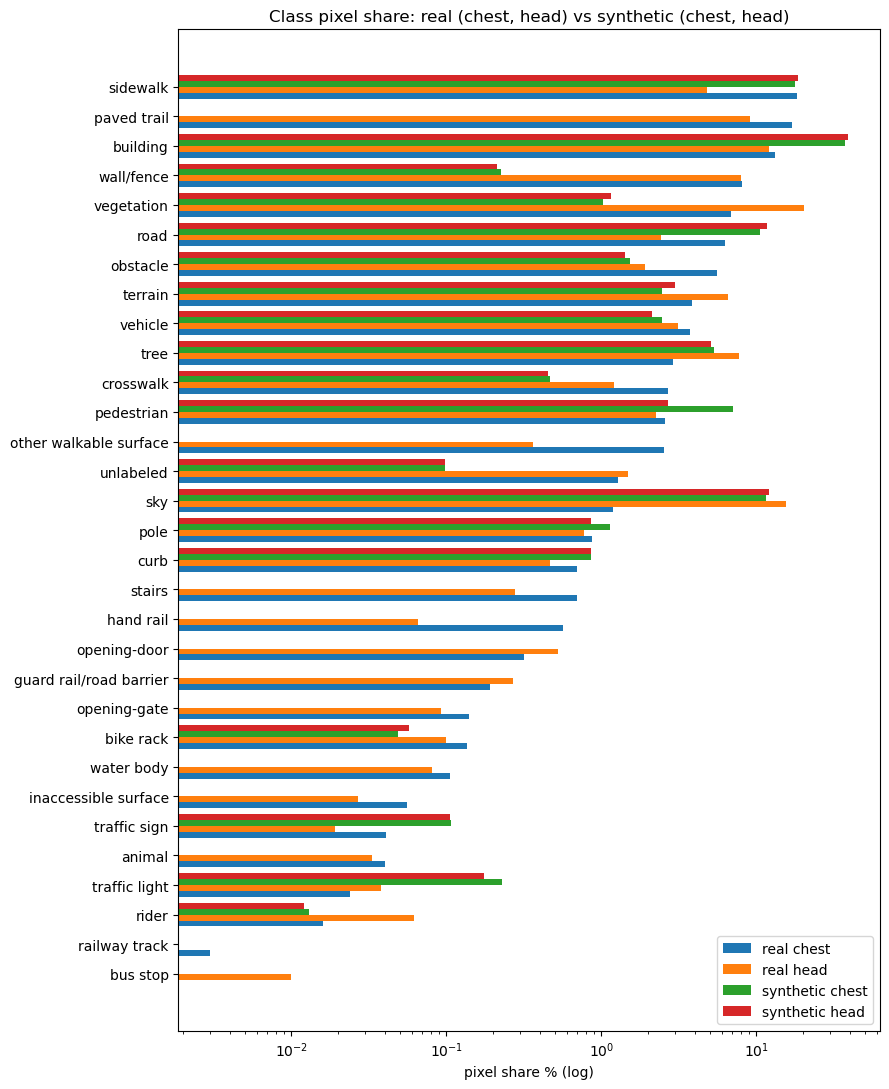

In [41]:
absent = [name for name in class_names if (pixels[name] > 0).sum() == 0]
rare = comparison[(comparison[("synthetic chest", "frames %")] < 1) | (comparison[("synthetic head", "frames %")] < 1)]
print("classes absent from ALL synthetic frames:", absent)
print("bus stop pixels in synthetic:", int(pixels["bus stop"].sum()), "(ignored in training, like the real data)")
print("\nclasses in fewer than 1% of the frames of one camera:")
display(rare)
order = comparison.sort_values(("real chest", "pixel %"), ascending=True).index
figure, axis = plt.subplots(figsize=(9, 11))
y = np.arange(len(order))
groups = ("real chest", "real head", "synthetic chest", "synthetic head")
for offset, column in zip((-0.3, -0.1, 0.1, 0.3), groups):
    axis.barh(y + offset, comparison.loc[order, (column, "pixel %")], height=0.2, label=column)
axis.set_yticks(y, order); axis.set_xscale("log"); axis.set_xlabel("pixel share % (log)"); axis.legend()
axis.set_title("Class pixel share: real (chest, head) vs synthetic (chest, head)")
plt.tight_layout(); plt.show()

## 7. Sample frames and masks

✓ Initialized. View run at 
https://modal.com/apps/third-workspace/main/ap-fwXVHy6ryPDgY98hFpsQR1
- Initializing...
| Creating objects...objects...
├── - Creating function read_indexes...
├── - Creating function class_pixels_of_walk...
- Creating objects...
├── | Creating function read_indexes...
├── 🔨 Created function class_pixels_of_walk.
- Creating objects...
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
✓ Created objects.
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
- Running... View app at 
| Running... View app at DgY98hFpsQR1
- Running... View app at DgY98hFpsQR1
| Running... View app at DgY98hFpsQR1
- Running... View app at DgY98hFpsQR1
| Running... View app at DgY98hFpsQR1
Volume mounted at /data is using 85.1% of available inodes (425714 out of 500000). If you reach the limit, creating new files will fail.
- Loading images (1 con

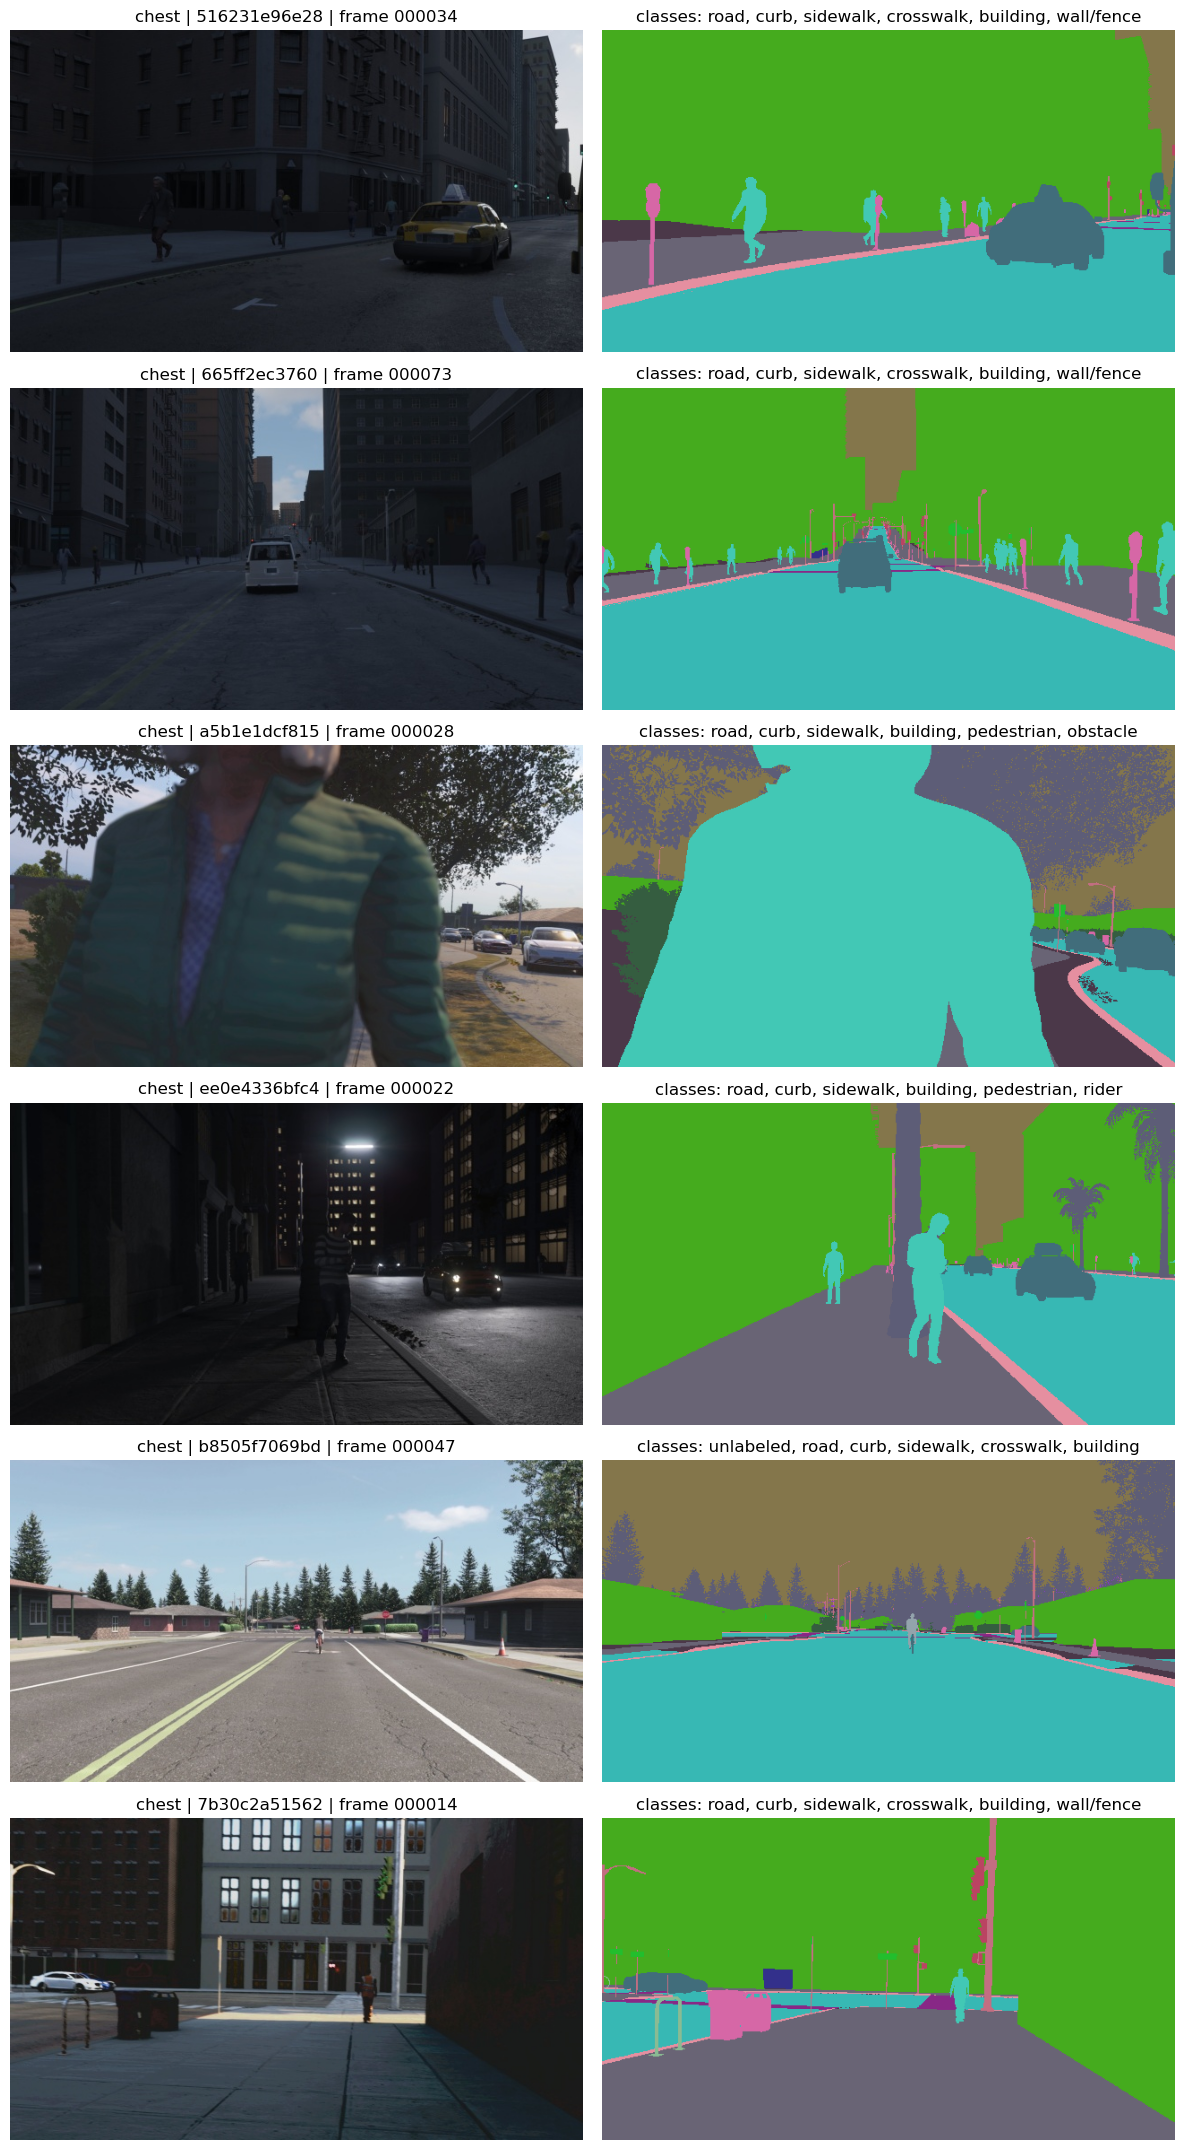

In [42]:
sample = frames.sample(SAMPLE_IMAGES, random_state=SEED)
with modal.enable_output(), app.run():
    # sample_images takes: (frame path, mask path) pairs; returns: (JPG bytes, mask PNG bytes) at 640 px wide
    images = sample_images.remote(list(zip(sample["frame"], sample["mask"])))
colors = np.random.default_rng(SEED).integers(30, 230, (256, 3), dtype=np.uint8)
figure, axes = plt.subplots(SAMPLE_IMAGES, 2, figsize=(12, 3.6 * SAMPLE_IMAGES), squeeze=False)
for (_, row), (frame_bytes, mask_bytes), (left, right) in zip(sample.iterrows(), images, axes):
    frame = cv2.cvtColor(cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
    mask = cv2.imdecode(np.frombuffer(mask_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
    left.imshow(frame); left.set_title(f"{row['camera']} | {row['session'][:12]} | frame {row['frame_id']}")
    right.imshow(colors[mask]); right.set_title("classes: " + ", ".join(class_names[i] for i in np.unique(mask)[:6]))
    left.axis("off"); right.axis("off")
plt.tight_layout(); plt.show()

## 8. Summary for the next steps

Fill in after running: frame-rate groups found (and how clean the separation is), frames after thinning to about
5 FPS, classes missing or rare in synthetic data, anything unexpected. These decide the validation split
(`validation_split/`) and the training setups.

## 9. Random frames from all 4 groups

Independent of the sections above (it only needs the loaded tables): a few random frames with their masks from the real
chest, real head, synthetic chest and synthetic head data, the same class colors everywhere. Run it again with another
`SAMPLE_SEED` for other frames.

✓ Initialized. View run at 
https://modal.com/apps/third-workspace/main/ap-g4osgsMPNDYCtk3FlioFE1
- Initializing...
- Creating objects...objects...
├── - Creating function read_indexes...
├── 🔨 Created function class_pixels_of_walk.
- Creating objects...
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
✓ Created objects.
├── 🔨 Created function read_indexes.
├── 🔨 Created function class_pixels_of_walk.
└── 🔨 Created function sample_images.
| Running... View app at 
- Running... View app at YCtk3FlioFE1
| Running... View app at YCtk3FlioFE1
- Running... View app at YCtk3FlioFE1
| Running... View app at YCtk3FlioFE1
- Running... View app at YCtk3FlioFE1
Volume mounted at /data is using 85.1% of available inodes (425714 out of 500000). If you reach the limit, creating new files will fail.
| Loading images (1 containers initializing)... View app at com/apps/third-workspace/main/ap-g4osgsM
- Loading images (1 containers i

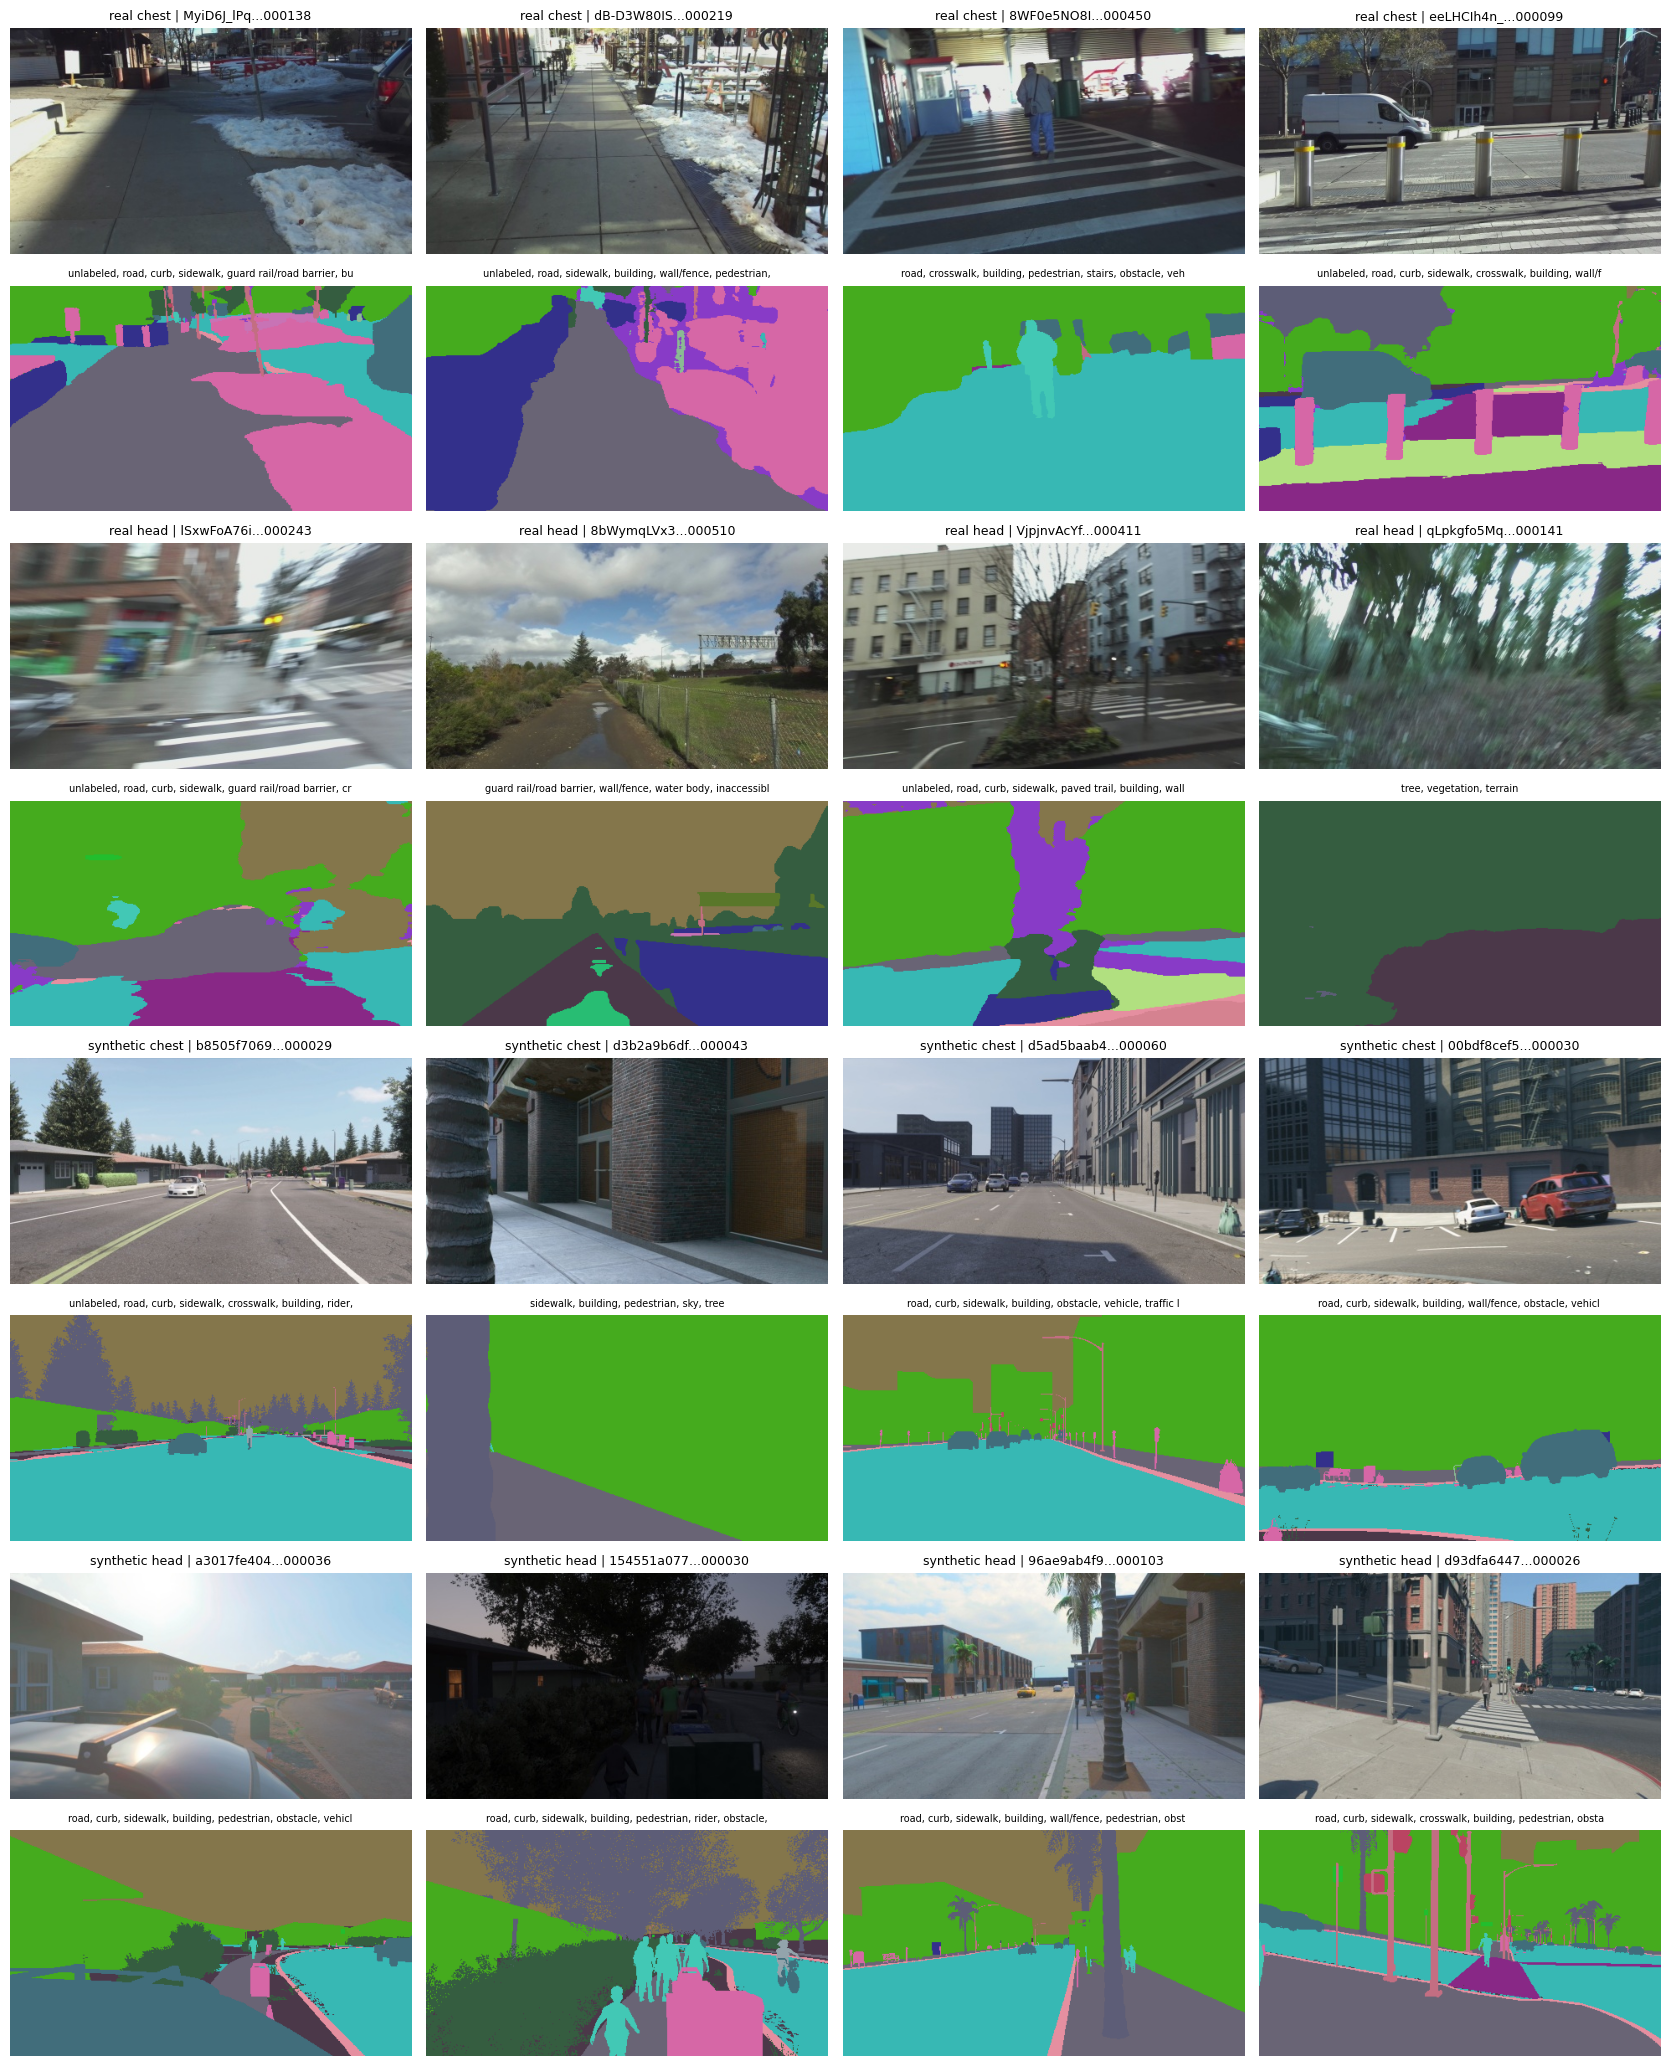

In [43]:
SAMPLES_PER_GROUP = 4             # random frames shown per group
SAMPLE_SEED = 7                   # change it for other frames
REAL_CHEST_DATASET = "sanpo_real_chest"   # the real chest folder on the same Modal session


def frame_of(mask_path: str) -> str:
    """masks/<split>/<stem>.png -> frames/<split>/<stem>.jpg (the same layout in every dataset folder)."""
    return mask_path.replace("masks/", "frames/", 1).rsplit(".", 1)[0] + ".jpg"


groups = {   # name: (dataset folder on the volume, mask paths to draw from)
    "real chest": (REAL_CHEST_DATASET, real["mask"]),
    "real head": (REAL_HEAD_DATASET, real_head["mask"]),
    "synthetic chest": (DATASET, pixels.loc[pixels["camera"] == "chest", "mask"]),
    "synthetic head": (DATASET, pixels.loc[pixels["camera"] == "head", "mask"]),
}
chosen = {name: masks.sample(SAMPLES_PER_GROUP, random_state=SAMPLE_SEED).tolist() for name, (_, masks) in groups.items()}
with modal.enable_output(), app.run():
    # sample_images takes: (frame path, mask path) pairs, width, dataset folder; returns: (JPG bytes, mask PNG bytes)
    fetched = {name: sample_images.remote([(frame_of(m), m) for m in chosen[name]], 480, groups[name][0])
               for name in groups}
colors = np.random.default_rng(SEED).integers(30, 230, (256, 3), dtype=np.uint8)   # one color per class id, everywhere
figure, axes = plt.subplots(2 * len(groups), SAMPLES_PER_GROUP, figsize=(4.2 * SAMPLES_PER_GROUP, 2.6 * 2 * len(groups)),
                            squeeze=False)
for row, name in enumerate(groups):
    for column, ((frame_bytes, mask_bytes), mask_path) in enumerate(zip(fetched[name], chosen[name])):
        frame = cv2.cvtColor(cv2.imdecode(np.frombuffer(frame_bytes, np.uint8), cv2.IMREAD_COLOR), cv2.COLOR_BGR2RGB)
        mask = cv2.imdecode(np.frombuffer(mask_bytes, np.uint8), cv2.IMREAD_UNCHANGED)
        top, bottom = axes[2 * row, column], axes[2 * row + 1, column]
        top.imshow(frame); top.set_title(f"{name} | {Path(mask_path).stem[:10]}...{Path(mask_path).stem[-6:]}", fontsize=9)
        bottom.imshow(colors[mask]); bottom.set_title(", ".join(class_names[i] for i in np.unique(mask) if i < 31)[:60],
                                                      fontsize=7)
        top.axis("off"); bottom.axis("off")
plt.tight_layout(); plt.show()